<a href="https://colab.research.google.com/github/onishchenkoanastasia5-glitch/Machine_learning/blob/main/%D0%9B%D0%A02_3_%D0%9E%D0%BD%D0%B8%D1%89%D0%B5%D0%BD%D0%BA%D0%BE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №2.3
Аналіз даних: коефіцієнт народжуваності в регіонах України (1950-2019)

Студентка: Онищенко Анастасія

**Крок 1.** Імпорт бібліотек

In [21]:
import pandas as pd
import matplotlib.pyplot as plt

**Крок 2.** Зчитуємо таблицю з Вікіпедії.
match шукає потрібну таблицю на сторінці, decimal="," бо числа записані через кому, storage_options з User-Agent щоб сайт не заблокував запит.

In [22]:
# посилання на статтю

from urllib.parse import quote
url = "https://uk.wikipedia.org/wiki/" + quote("Населення_України")

tables = pd.read_html(url, match="народжуваності", decimal=",", thousands=" ",
                      storage_options={"User-Agent": "Mozilla/5.0"})

t = tables[0]
t.head(10)

,Регіон,1950,1960,1970,1990,2000,2012,2014,2019
0,Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
1,Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
2,Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
3,Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
4,Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—
5,Житомирська,26.1,22.3,15.9,12.9,8.9,12.2,12.0,7.9
6,Закарпатська,31.4,27.3,20.7,16.8,11.5,15.1,14.6,10.4
7,Запорізька,21.9,19.7,15.0,12.4,7.1,10.6,10.6,6.8
8,Івано-Франківська,24.3,24.8,18.2,15.5,10.3,12.4,12.2,8.8
9,Київська,20.4,18.9,15.6,12.3,7.3,12.2,12.1,8.0


**Крок 3.** Розмір і типи даних

In [23]:
print(t.shape)
print(t.dtypes)

(28, 9)
Регіон     object
1950      float64
1960      float64
1970      float64
1990      float64
2000      float64
2012      float64
2014       object
2019       object
dtype: object


**Крок 4.** Робимо регіони індексом таблиці. Так простіше діставати потрібний рядок, наприклад t.loc["Україна"].

In [24]:
# назви колонок робимо рядками
t.columns = t.columns.astype(str)

t = t.set_index("Регіон")
t.head()

,1950,1960,1970,1990,2000,2012,2014,2019
Регіон,,,,,,,,
Крим,23.0,20.6,16.0,13.0,7.3,12.6,—,—
Вінницька,22.4,19.2,14.2,12.4,8.4,11.2,10.9,7.6
Волинська,24.7,25.0,17.9,15.3,11.2,14.8,14.1,10.1
Дніпропетровська,20.4,20.4,15.1,12.3,7.1,11.2,11.1,7.1
Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,—


**Крок 5.** Прочерки "—" означають, що даних немає. Замінюємо їх на NaN і переводимо всю таблицю в числа.

In [25]:
t = t.replace("—", float("nan"))
t = t.astype(float)

t.dtypes

,0
1950,float64
1960,float64
1970,float64
1990,float64
2000,float64
2012,float64
2014,float64
2019,float64


**Крок 6.** Пропуски

In [26]:
print("Всього пропусків:", t.isnull().sum().sum())


t[t.isnull().any(axis=1)]

Всього пропусків: 10


,1950,1960,1970,1990,2000,2012,2014,2019
Регіон,,,,,,,,
Крим,23.0,20.6,16.0,13.0,7.3,12.6,NaN,NaN
Донецька,27.1,21.4,14.0,10.9,6.1,9.8,8.2,NaN
Луганська,26.2,23.5,14.4,11.6,6.2,9.6,5.1,NaN
Київ,NaN,17.4,15.9,12.0,7.3,12.0,12.1,11.0
Севастополь,NaN,NaN,NaN,12.5,7.0,12.0,NaN,NaN


Пропуски не заповнюємо і не видаляємо. Функції mean() і std() в pandas самі пропускають NaN, тому для кожного року рахуються тільки ті регіони, де є дані.

**Крок 7.** Окремо рядок "Україна" і окремо регіони

In [27]:
ukr = t.loc["Україна"]
reg = t.drop("Україна")

print("Регіонів:", len(reg))
print()
print(ukr)

Регіонів: 27

1950    22.8
1960    20.5
1970    15.2
1990    12.6
2000     7.8
2012    11.4
2014    11.1
2019     8.1
Name: Україна, dtype: float64


**Крок 8.** Порівнюємо середнє по регіонах з показником по Україні

In [28]:
compare = pd.DataFrame({"Середнє по регіонах": reg.mean(), "Україна": ukr})
compare.round(2)

,Середнє по регіонах,Україна
1950,23.10,22.8
1960,20.76,20.5
1970,15.60,15.2
1990,13.06,12.6
2000,8.22,7.8
2012,11.66,11.4
2014,11.14,11.1
2019,8.02,8.1


**Крок 9.** На скільки відсотків змінилась народжуваність з 1950 по 2019 у кожному регіоні.
Формула: (2019 - 1950) / 1950 * 100. Регіони, де немає одного з цих років, прибираємо через dropna().

In [29]:
change = (reg["2019"] - reg["1950"]) / reg["1950"] * 100
change = change.dropna().round(1)

change.sort_values()

,0
Регіон,
Чернігівська,-72.3
Сумська,-72.2
Житомирська,-69.7
Запорізька,-68.9
Черкаська,-68.8
Кіровоградська,-68.5
Закарпатська,-66.9
Миколаївська,-66.4
Хмельницька,-66.2


In [30]:
# по Україні
ukr_change = (ukr["2019"] - ukr["1950"]) / ukr["1950"] * 100
print("Україна:", round(ukr_change, 1), "%")

Україна: -64.5 %


**Крок 10.** Перевіряємо дві хвилі: чи був ріст з 2000 по 2012 і чи було падіння з 2012 по 2019.

In [31]:
growth = reg["2012"] > reg["2000"]
print("Регіонів, де у 2012 більше, ніж у 2000:", growth.sum(), "з", len(reg))

# беремо тільки регіони, де є і 2012, і 2019
temp = reg[["2012", "2019"]].dropna()
fall = temp["2019"] < temp["2012"]
print("Регіонів, де у 2019 менше, ніж у 2012:", fall.sum(), "з", len(temp))

Регіонів, де у 2012 більше, ніж у 2000: 27 з 27
Регіонів, де у 2019 менше, ніж у 2012: 23 з 23


**Крок 11.** Розкид між регіонами (стандартне відхилення) по кожному року. Чим він менший, тим регіони ближчі один до одного.

In [32]:
spread = reg.std().round(2)
spread

,0
1950,2.88
1960,2.99
1970,1.91
1990,1.55
2000,1.58
2012,1.67
2014,2.05
2019,1.48


## Графіки
Графіки будуємо через .plot() в pandas, він сам підписує осі і легенду.

**Графік 1.** Середня народжуваність по регіонах у кожному році

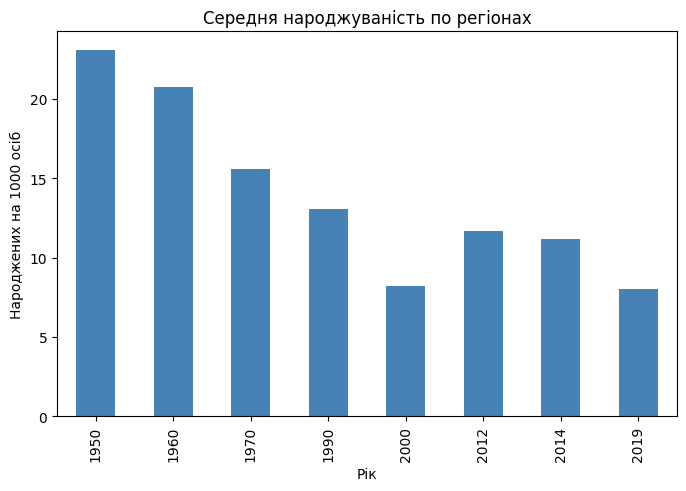

In [33]:
reg.mean().plot(kind="bar", figsize=(8, 5), color="steelblue")
plt.title("Середня народжуваність по регіонах")
plt.xlabel("Рік")
plt.ylabel("Народжених на 1000 осіб")
plt.show()

**Графік 2.** Зміна народжуваності з 1950 по 2019 у відсотках. Чим довший стовпчик, тим сильніше впала народжуваність.

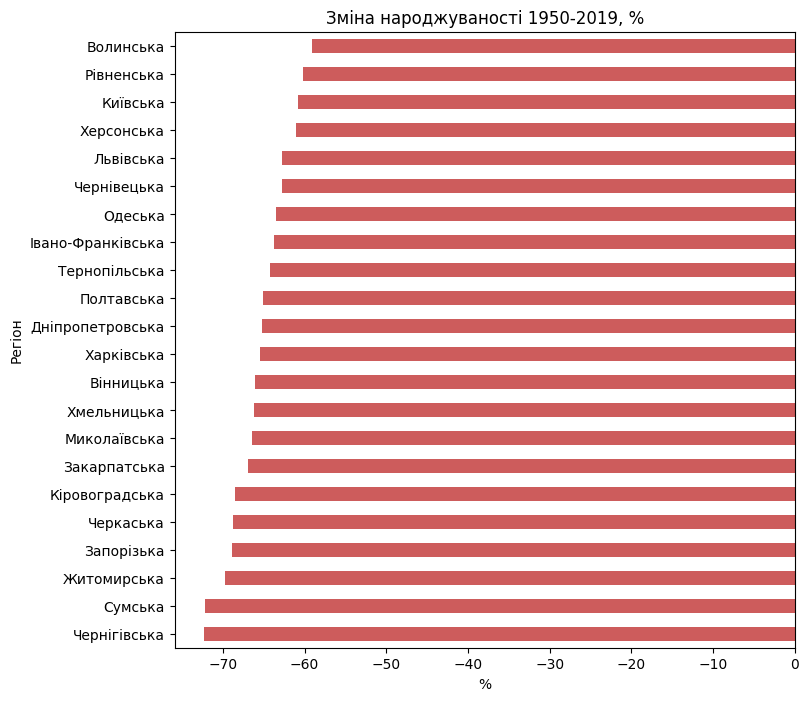

In [34]:
change.sort_values().plot(kind="barh", figsize=(8, 8), color="indianred")
plt.title("Зміна народжуваності 1950-2019, %")
plt.xlabel("%")
plt.show()

**Графік 3.** Динаміка по Україні і трьох областях.
.T перевертає таблицю, щоб роки були по осі X. Роки переводимо в числа, щоб відстані між ними на графіку були правильні (між 1970 і 1990 двадцять років).

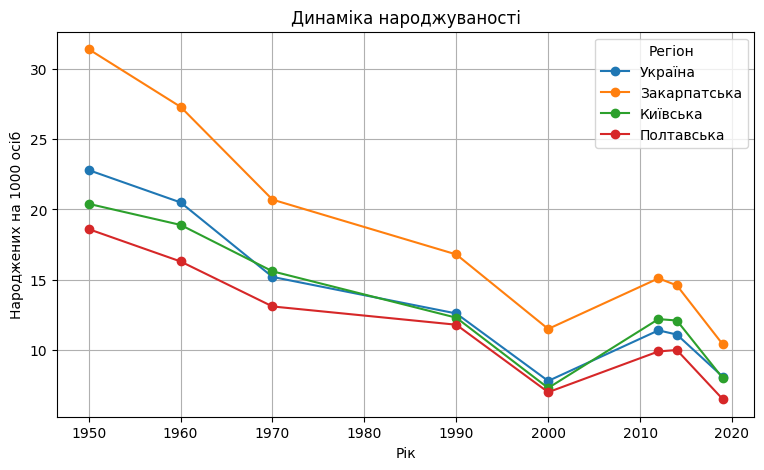

In [35]:
lines = t.loc[["Україна", "Закарпатська", "Київська", "Полтавська"]].T
lines.index = lines.index.astype(int)

lines.plot(marker="o", figsize=(9, 5))
plt.title("Динаміка народжуваності")
plt.xlabel("Рік")
plt.ylabel("Народжених на 1000 осіб")
plt.grid()
plt.show()

**Графік 4.** Порівняння 2000, 2012 і 2019 років по всіх регіонах. Видно ріст до 2012 і падіння після.

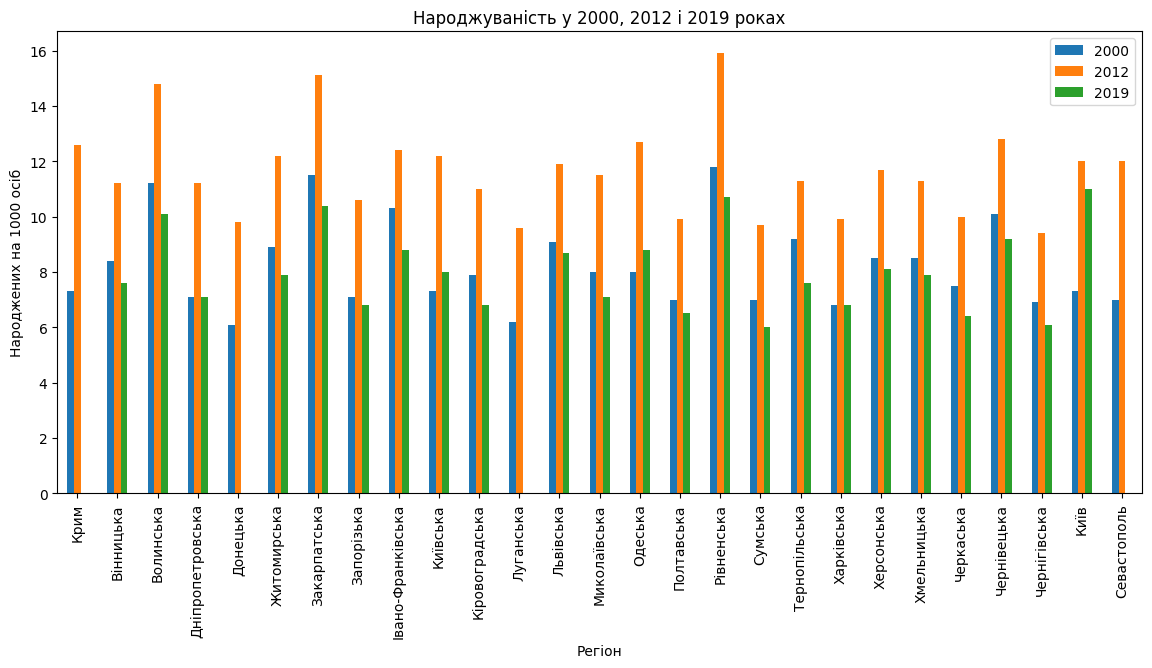

In [36]:
reg[["2000", "2012", "2019"]].plot(kind="bar", figsize=(14, 6))
plt.title("Народжуваність у 2000, 2012 і 2019 роках")
plt.ylabel("Народжених на 1000 осіб")
plt.show()

**Графік 5.** Як змінювався розкид між регіонами

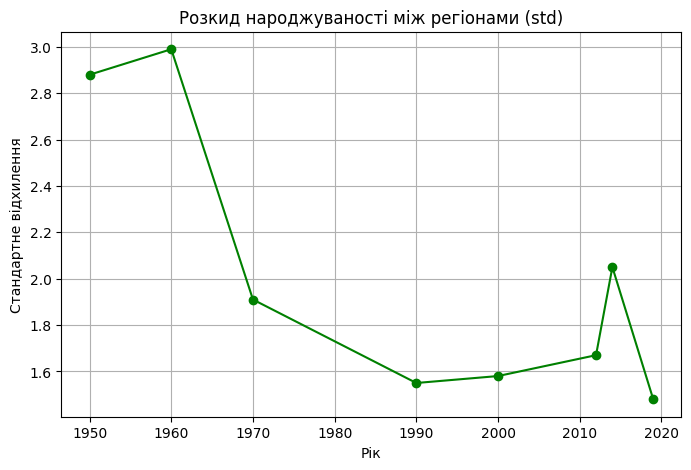

In [37]:
spread.index = spread.index.astype(int)

spread.plot(marker="o", figsize=(8, 5), color="green")
plt.title("Розкид народжуваності між регіонами (std)")
plt.xlabel("Рік")
plt.ylabel("Стандартне відхилення")
plt.grid()
plt.show()

In [38]:
# ПЕРЕВІРКА висновків: порівняй ці числа з текстом нижче
print("1) Україна 1950 -> 2019:", ukr["1950"], "->", ukr["2019"], "| зміна:", round(ukr_change, 1), "%")
print("2) макс. різниця середнього по регіонах і України:", round((compare["Середнє по регіонах"] - compare["Україна"]).abs().max(), 2))
ch = change.sort_values()
print("3) найменше падіння:\n", ch.head(3), "\n   найбільше падіння:\n", ch.tail(3))
print("4) ріст 2000->2012:", growth.sum(), "з", len(reg), "| падіння 2012->2019:", fall.sum(), "з", len(temp))
print("5) Закарпатська > Україна у всіх роках:", (t.loc["Закарпатська"] > ukr).all(),
      "| Полтавська < Україна у всіх роках:", (t.loc["Полтавська"] < ukr).all())
print("6) розкид (std) 1950 ->", spread.iloc[0], "| 2019 ->", spread.iloc[-1])
print("7) пропуски:", {r: list(t.columns[t.loc[r].isnull()]) for r in t.index[t.isnull().any(axis=1)]})

1) Україна 1950 -> 2019: 22.8 -> 8.1 | зміна: -64.5 %
2) макс. різниця середнього по регіонах і України: 0.46
3) найменше падіння:
 Регіон
Чернігівська   -72.3
Сумська        -72.2
Житомирська    -69.7
dtype: float64 
   найбільше падіння:
 Регіон
Київська     -60.8
Рівненська   -60.2
Волинська    -59.1
dtype: float64
4) ріст 2000->2012: 27 з 27 | падіння 2012->2019: 23 з 23
5) Закарпатська > Україна у всіх роках: True | Полтавська < Україна у всіх роках: True
6) розкид (std) 1950 -> 2.88 | 2019 -> 1.48
7) пропуски: {'Крим': ['2014', '2019'], 'Донецька': ['2019'], 'Луганська': ['2019'], 'Київ': ['1950'], 'Севастополь': ['1950', '1960', '1970', '2014', '2019']}


## Висновки

1. З 1950 по 2019 народжуваність в Україні впала з 22.8 до 8.1 на 1000 осіб, тобто приблизно на 64.5%.
2. Середнє по регіонах майже збігається з показником по Україні, тому середнє можна використовувати для порівняння.
3. У відсотках найменше впала народжуваність у Волинській і Рівненській областях (приблизно на 59-60%), найбільше у Чернігівській і Сумській (приблизно на 72%).
4. Було дві хвилі: з 2000 по 2012 народжуваність зросла в усіх регіонах, а з 2012 по 2019 знову впала в усіх регіонах, де є дані.
5. Закарпатська область весь час вища за Україну, а Полтавська нижча, але всі лінії йдуть вниз приблизно однаково.
6. Розкид між регіонами з роками зменшився, тобто регіони стали більш схожими між собою.
7. По Криму і Севастополю немає даних за 2014 і 2019, по Донецькій і Луганській за 2019, по Києву за 1950. Ці значення не заповнювались, тому у відсотковій зміні цих регіонів немає.